In [2]:
import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter
from ultralytics import YOLO

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
PROJECT_DIR = Path("..")

IMAGE_DIR = PROJECT_DIR / "sample_images"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "images"
MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Image directory:", IMAGE_DIR.resolve())
print("Output directory:", OUTPUT_DIR.resolve())
print("Model directory:", MODEL_DIR.resolve())

Image directory: D:\ObjectDetection\sample_images
Output directory: D:\ObjectDetection\outputs\images
Model directory: D:\ObjectDetection\models


In [4]:
model_path = MODEL_DIR / "yolov8n.pt"

model = YOLO(str(model_path))

print("YOLOv8 model loaded successfully!")

YOLOv8 model loaded successfully!


Image loaded successfully!
Image shape: (1080, 810, 3)


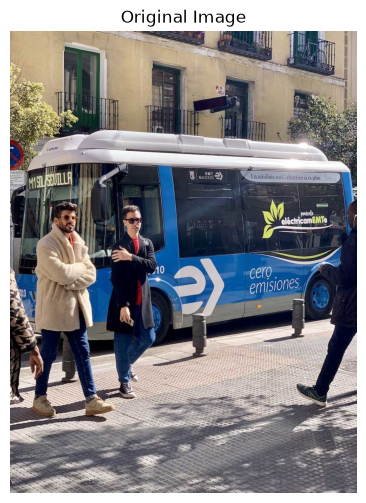

In [5]:
image_path = IMAGE_DIR / "bus.jpg"

image = cv2.imread(str(image_path))

if image is None:
    raise FileNotFoundError(f"Image not found: {image_path}")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image loaded successfully!")
print("Image shape:", image.shape)

plt.figure(figsize=(10, 6))
plt.imshow(image_rgb)
plt.axis("off")
plt.title("Original Image")
plt.show()

In [6]:
results = model.predict(
    source=str(image_path),
    conf=0.25,
    iou=0.45,
    imgsz=640,
    verbose=False
)

result = results[0]

print("Detection completed!")
print("Total objects detected:", len(result.boxes))

Detection completed!
Total objects detected: 6


In [7]:
boxes = result.boxes.xyxy.cpu().numpy()

print("Bounding Boxes:")
print(boxes)

Bounding Boxes:
[[     22.871      231.28         805      756.84]
 [      48.55      398.55      245.35       902.7]
 [     669.47      392.19      809.72      877.04]
 [     221.52       405.8      344.97      857.54]
 [          0      550.53      63.007      873.44]
 [   0.058174      254.46      32.557      324.87]]


In [8]:
class_ids = result.boxes.cls.cpu().numpy().astype(int)

confidences = result.boxes.conf.cpu().numpy()

class_names = model.names

for class_id, confidence in zip(class_ids, confidences):

    object_name = class_names[class_id]

    print(
        f"Object: {object_name} | "
        f"Confidence: {confidence:.2%}"
    )

Object: bus | Confidence: 87.34%
Object: person | Confidence: 86.57%
Object: person | Confidence: 85.28%
Object: person | Confidence: 82.52%
Object: person | Confidence: 26.11%
Object: stop sign | Confidence: 25.51%


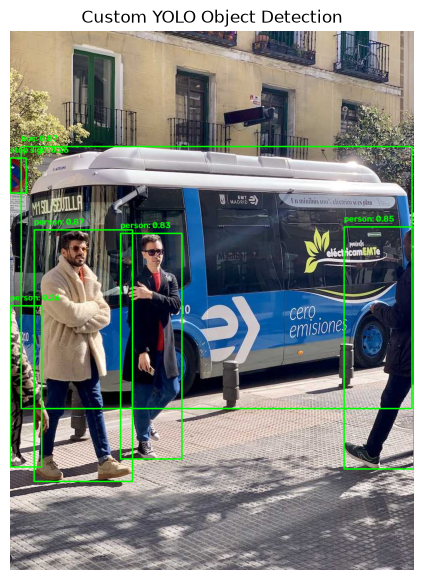

In [9]:
image_copy = image.copy()

for box, class_id, confidence in zip(
    boxes, class_ids, confidences
):

    x1, y1, x2, y2 = map(int, box)

    class_name = model.names[class_id]

    label = f"{class_name}: {confidence:.2f}"

    # Draw rectangle
    cv2.rectangle(
        image_copy,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

    # Draw label
    cv2.putText(
        image_copy,
        label,
        (x1, max(y1 - 10, 20)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        (0, 255, 0),
        2
    )

image_copy_rgb = cv2.cvtColor(
    image_copy,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(image_copy_rgb)
plt.title("Custom YOLO Object Detection")
plt.axis("off")
plt.show()

In [10]:
detected_names = [
    model.names[class_id]
    for class_id in class_ids
]

object_counts = Counter(detected_names)

print("OBJECT DETECTION REPORT")
print("-" * 30)

for object_name, count in object_counts.items():

    print(f"{object_name}: {count}")

print("-" * 30)

print("Total Objects:", sum(object_counts.values()))

OBJECT DETECTION REPORT
------------------------------
bus: 1
person: 4
stop sign: 1
------------------------------
Total Objects: 6


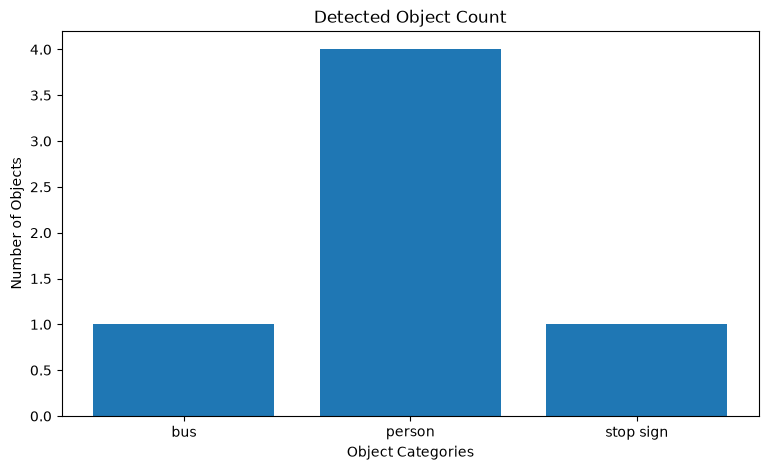

In [11]:
if object_counts:

    names = list(object_counts.keys())
    counts = list(object_counts.values())

    plt.figure(figsize=(9, 5))

    plt.bar(names, counts)

    plt.xlabel("Object Categories")
    plt.ylabel("Number of Objects")
    plt.title("Detected Object Count")

    plt.show()

else:
    print("No objects detected!")

In [12]:
def detect_image(image_path, confidence=0.25):

    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError(
            f"Could not load image: {image_path}"
        )

    results = model.predict(
        source=image,
        conf=confidence,
        verbose=False
    )

    result = results[0]

    annotated_image = result.plot()

    return result, annotated_image

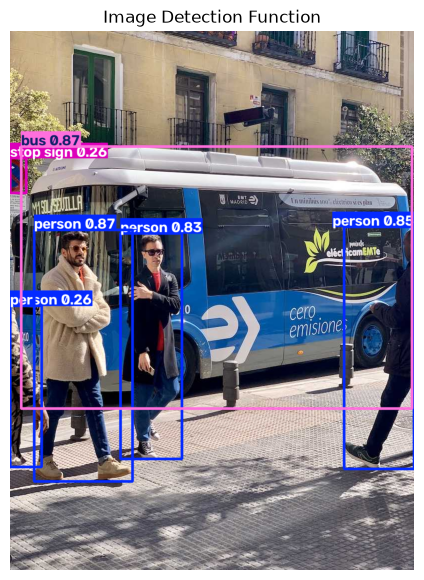

Detected objects: 6


In [13]:
result, detected_image = detect_image(
    IMAGE_DIR / "bus.jpg",
    confidence=0.25
)

detected_image_rgb = cv2.cvtColor(
    detected_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 7))
plt.imshow(detected_image_rgb)
plt.axis("off")
plt.title("Image Detection Function")
plt.show()

print("Detected objects:", len(result.boxes))

In [15]:
image_extensions = ["*.jpg", "*.jpeg", "*.png"]

image_files = []

for extension in image_extensions:
    image_files.extend(IMAGE_DIR.glob(extension))

print("Total images:", len(image_files))

for image_file in image_files:

    result, annotated_image = detect_image(
        image_file,
        confidence=0.25
    )

    save_path = OUTPUT_DIR / f"{image_file.stem}_detected.jpg"

    cv2.imwrite(str(save_path), annotated_image)

    print(
        f"{image_file.name} | "
        f"Objects detected: {len(result.boxes)} | "
        f"Saved: {save_path.name}"
    )

Total images: 3
bus.jpg | Objects detected: 6 | Saved: bus_detected.jpg
dream.jpg | Objects detected: 6 | Saved: dream_detected.jpg
test12.jpg | Objects detected: 20 | Saved: test12_detected.jpg


In [17]:
metrics = model.val(
    data="coco8.yaml",
    imgsz=640,
    batch=4,
    verbose=True
)

print("Validation completed!")

Ultralytics 8.4.191  Python-3.14.6 torch-2.14.0+cpu CPU (Intel Core 5 120U)
YOLOv8n summary (fused): 72 layers, 3,151,904 parameters, 0 gradients, 8.7 GFLOPs

WARNING Dataset 'coco8.yaml' images not found, missing path 'C:\Users\PRAWIN KUMAR\CNN\datasets\coco8\images\val'
Unzipping C:\Users\PRAWIN KUMAR\CNN\datasets\coco8.zip to C:\Users\PRAWIN KUMAR\CNN\datasets\coco8...: 100% ━━━━━━━━━━━━ 25/25 1.4Kfiles/s 0.0s
Dataset download success  (6.4s), saved to C:\Users\PRAWIN KUMAR\CNN\datasets

WARNING val: Slow image access detected (ping: 0.0±0.0 ms, read: 7.3±7.2 MB/s, size: 54.0 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\PRAWIN KUMAR\CNN\datasets\coco8\labels\val... 4 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 4/4 243.9it/s 0.0s
val: New cache created: C:\Users\PRAWIN KUMAR\CNN\datasets\coco8\labels\val.cache
                 Class     Images  Instances     

In [18]:
print("YOLOv8 Evaluation Results")
print("-" * 35)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP@0.5:", metrics.box.map50)
print("mAP@0.5:0.95:", metrics.box.map)

YOLOv8 Evaluation Results
-----------------------------------
Precision: 0.6209717894547008
Recall: 0.8333333333333334
mAP@0.5: 0.8957183257918552
mAP@0.5:0.95: 0.6298872061424038


In [19]:
def object_detection_pipeline(
    image_path,
    confidence=0.25,
    save_output=True
):

    # Read image
    image = cv2.imread(str(image_path))

    if image is None:
        raise FileNotFoundError("Image not found!")

    # YOLO prediction
    results = model.predict(
        source=image,
        conf=confidence,
        verbose=False
    )

    result = results[0]

    # Draw bounding boxes
    output_image = result.plot()

    # Extract classes
    class_ids = result.boxes.cls.cpu().numpy().astype(int)

    detected_names = [
        model.names[class_id]
        for class_id in class_ids
    ]

    # Count objects
    counts = Counter(detected_names)

    # Save output
    if save_output:

        output_path = (
            OUTPUT_DIR /
            f"{Path(image_path).stem}_result.jpg"
        )

        cv2.imwrite(str(output_path), output_image)

        print("Saved:", output_path)

    # Display image
    output_rgb = cv2.cvtColor(
        output_image,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(12, 7))
    plt.imshow(output_rgb)
    plt.axis("off")
    plt.title("Object Detection Result")
    plt.show()

    # Print report
    print("\nOBJECT DETECTION REPORT")
    print("-" * 35)

    for name, count in counts.items():
        print(f"{name}: {count}")

    print("-" * 35)
    print("Total objects:", len(result.boxes))

    return result, counts

Saved: ..\outputs\images\bus_result.jpg


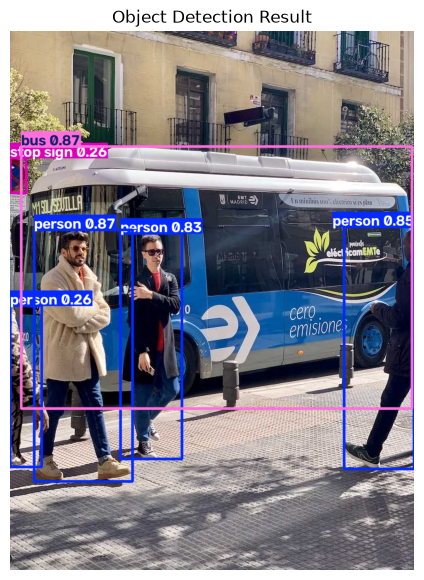


OBJECT DETECTION REPORT
-----------------------------------
bus: 1
person: 4
stop sign: 1
-----------------------------------
Total objects: 6


In [20]:
result, counts = object_detection_pipeline(
    IMAGE_DIR / "bus.jpg",
    confidence=0.25,
    save_output=True
)